Box-Cox Transform

- distribution convert into normal
- Its the general transform, log transform is the special case of this.
- Ranges from -5 to 5, we examine all values of lambda.
- Applicable to numbers greater than 0, (not 0 and not negative)


Yeo-Johnson Transform
- enhancement in Box-Cox, accepts negative and 0 values as well




In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import scipy.stats as stats

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer
 

In [3]:
df = pd.read_csv("../datasets/concrete_data.csv")

In [4]:
df.sample(5)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
689,157.0,236.0,0.0,192.0,0.0,935.4,781.2,7,16.89
531,436.0,0.0,0.0,218.0,0.0,838.4,719.7,28,23.85
766,385.0,0.0,0.0,186.0,0.0,966.0,763.0,14,27.92
871,159.0,187.0,0.0,176.0,11.0,990.0,789.0,28,32.76
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30


In [5]:
df.shape

(1030, 9)

In [6]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [7]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2, random_state=42
)

In [11]:
#Applying regression without any transformation

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

r2_score(y_test, y_pred)

0.6275531792314848

In [18]:
#Cross checking with cross val score

lr = LinearRegression()
np.mean(cross_val_score(lr,X,y,cv=5,scoring='r2'))

np.float64(0.4609940491662864)

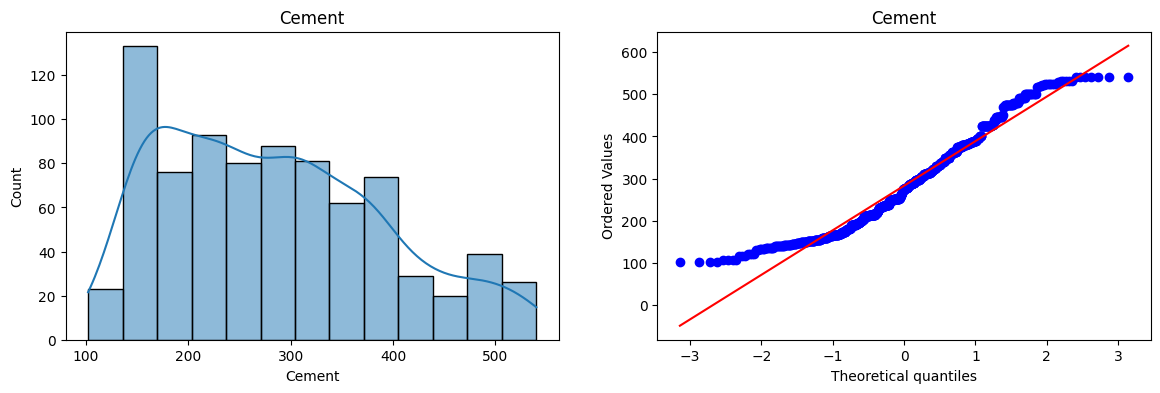

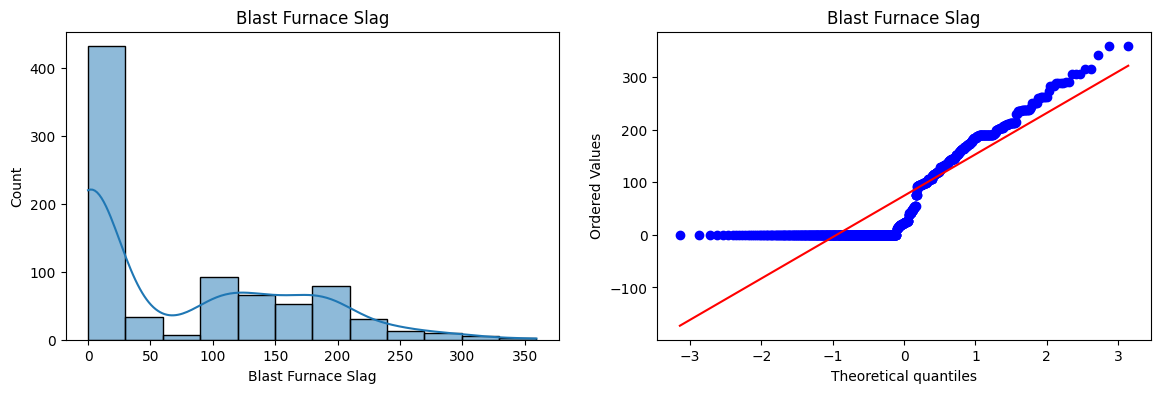

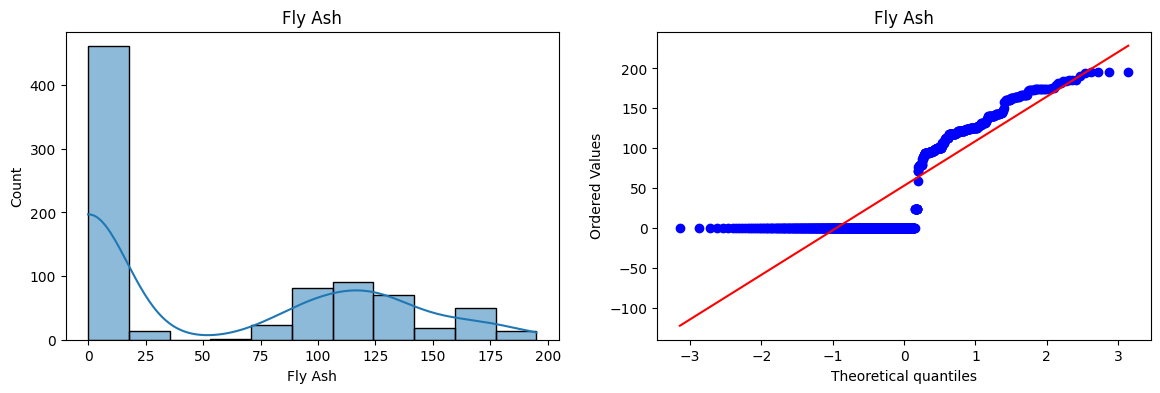

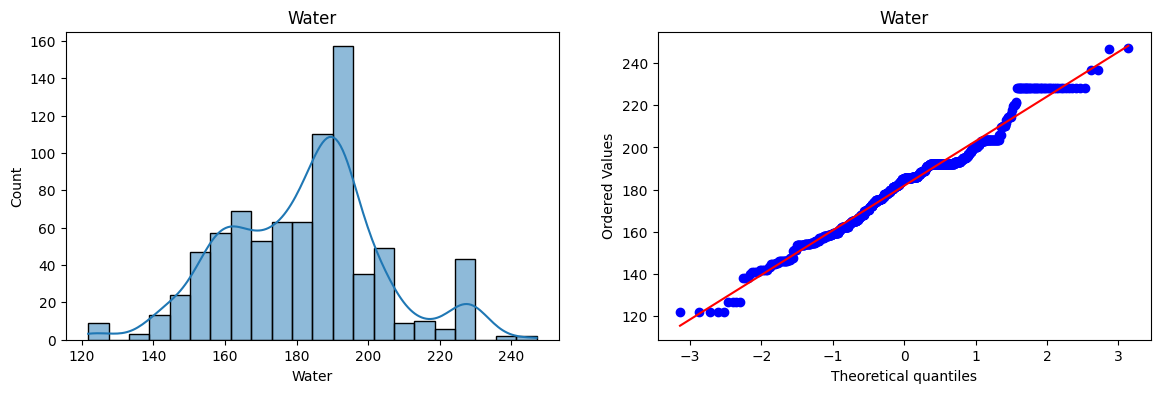

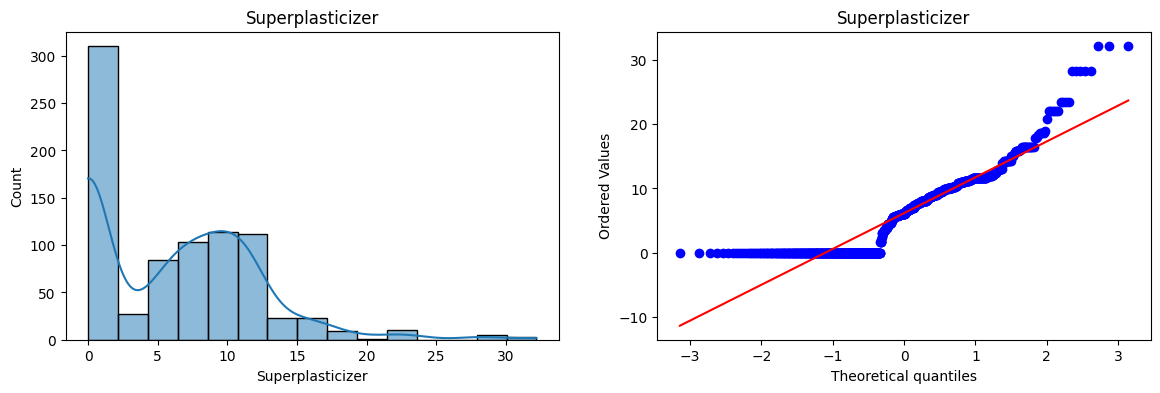

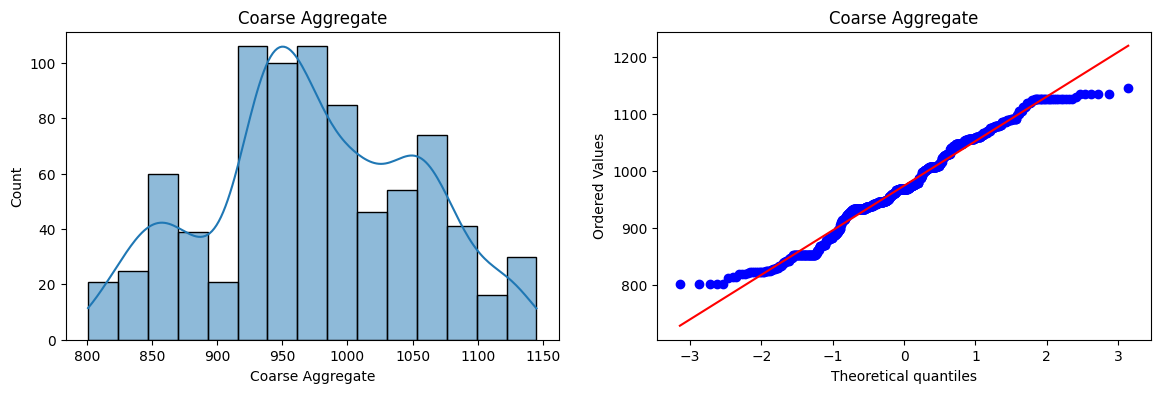

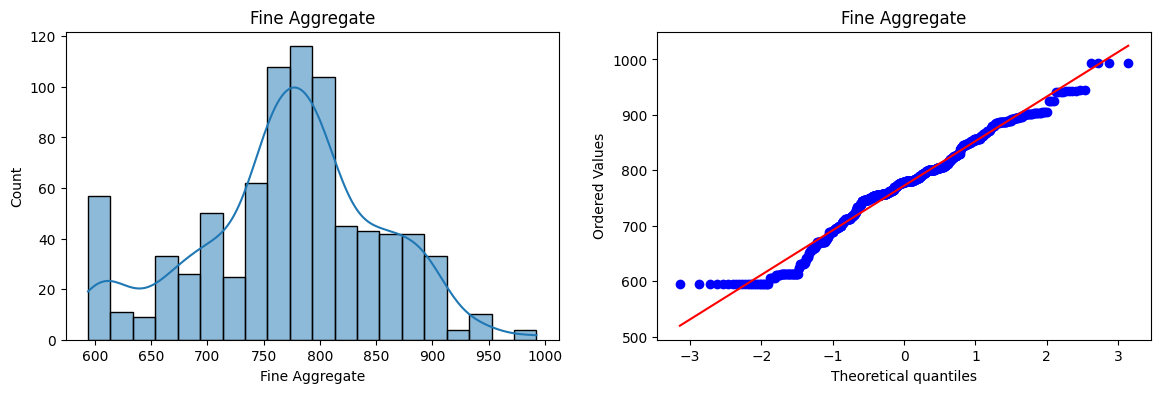

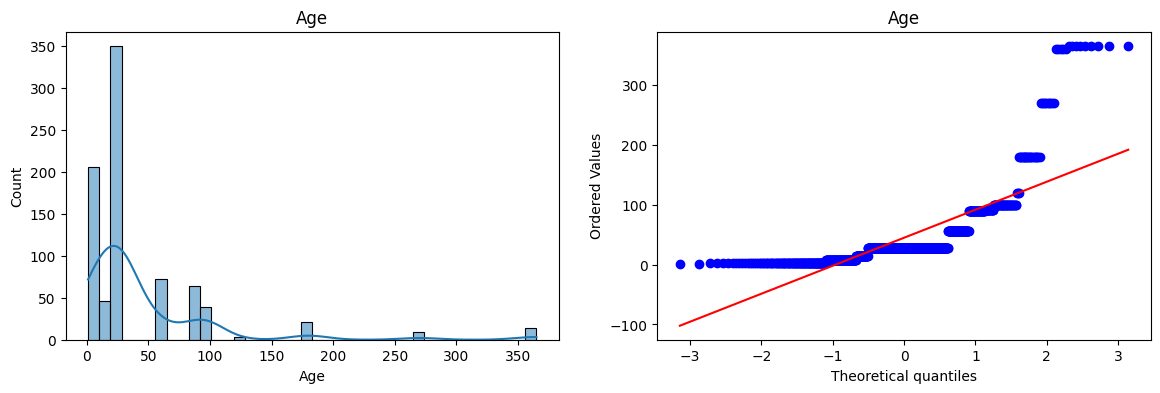

In [ ]:
#Plotting the distplots without any transformation

for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(col)
    
    plt.subplot(122)
    stats.probplot(X_train[col], dist='norm', plot = plt)
    plt.title(col)
    
    plt.show()

Lets do scaling

In [25]:
df.sample(5)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
619,254.0,0.0,0.0,198.0,0.0,968.0,863.0,180,27.63
646,250.2,166.8,0.0,203.5,0.0,977.6,694.1,90,47.71
462,172.4,13.6,172.4,156.8,4.1,1006.3,856.4,100,37.68
66,139.6,209.4,0.0,192.0,0.0,1047.0,806.9,360,44.70
1009,298.1,0.0,107.0,186.4,6.1,879.0,815.2,28,42.64


In [41]:
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import MinMaxScaler

scaled = ColumnTransformer(
    [('scale',MinMaxScaler(), slice(0,None))],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')
# slice(0,None) selectes all the indexs till the end

In [36]:
X_train

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
995,158.6,148.9,116.0,175.1,15.0,953.3,719.7,28
507,424.0,22.0,132.0,178.0,8.5,822.0,750.0,28
334,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,3
848,252.0,97.0,76.0,194.0,8.0,835.0,821.0,28
294,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,3
...,...,...,...,...,...,...,...,...
87,286.3,200.9,0.0,144.7,11.2,1004.6,803.7,3
330,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,14
466,190.3,0.0,125.2,166.6,9.9,1079.0,798.9,100
121,475.0,118.8,0.0,181.1,8.9,852.1,781.5,28


In [42]:
X_train_scaled = scaled.fit_transform(X_train)
X_test_scaled = scaled.transform(X_test)

In [43]:
X_train_scaled

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
995,0.129224,0.414302,0.594872,0.425719,0.465839,0.442733,0.315354,0.074176
507,0.735160,0.061213,0.676923,0.448882,0.263975,0.061047,0.391370,0.074176
334,0.395205,0.000000,0.622564,0.301118,0.307453,0.734302,0.460361,0.005495
848,0.342466,0.269894,0.389744,0.576677,0.248447,0.098837,0.569493,0.074176
294,0.152740,0.117418,0.637436,0.291534,0.335404,0.813372,0.507275,0.005495
...,...,...,...,...,...,...,...,...
87,0.420776,0.558987,0.000000,0.182907,0.347826,0.591860,0.526091,0.005495
330,0.330594,0.000000,0.641538,0.171725,0.372671,0.830814,0.519067,0.035714
466,0.201598,0.000000,0.642051,0.357827,0.307453,0.808140,0.514049,0.271978
121,0.851598,0.330551,0.000000,0.473642,0.276398,0.148547,0.470396,0.074176


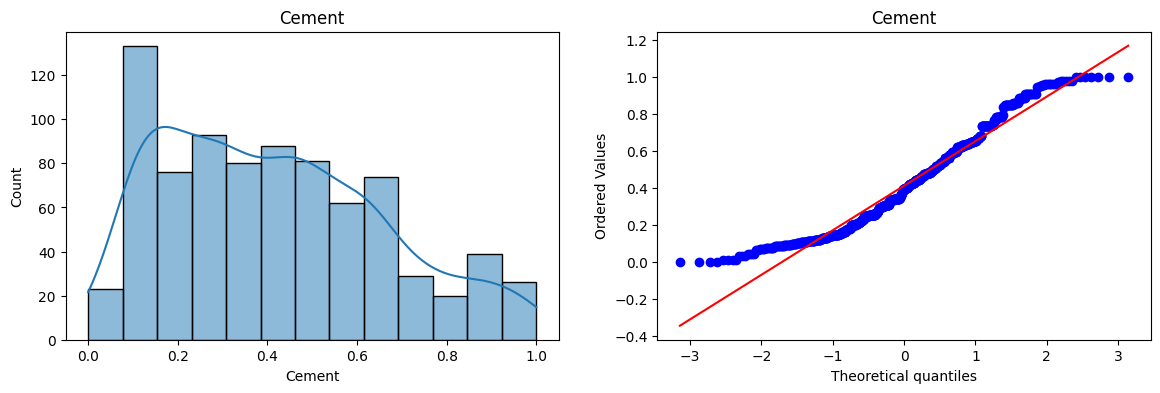

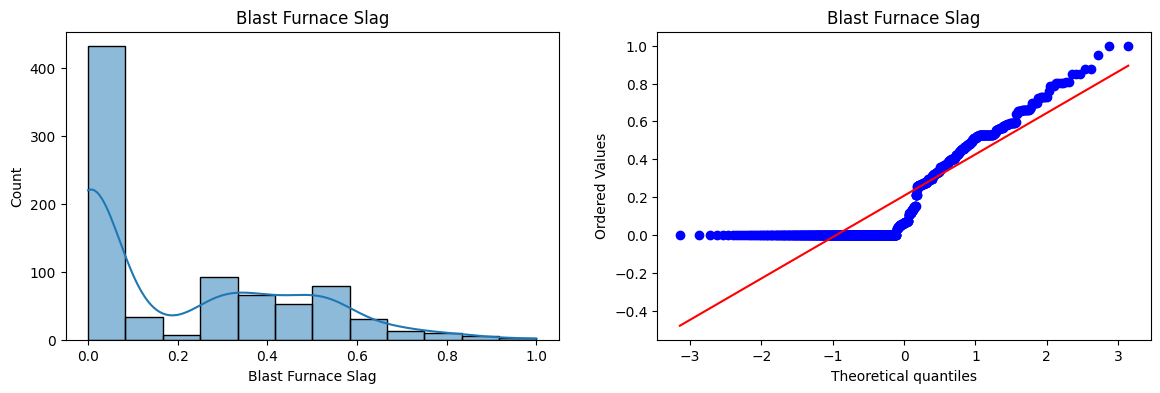

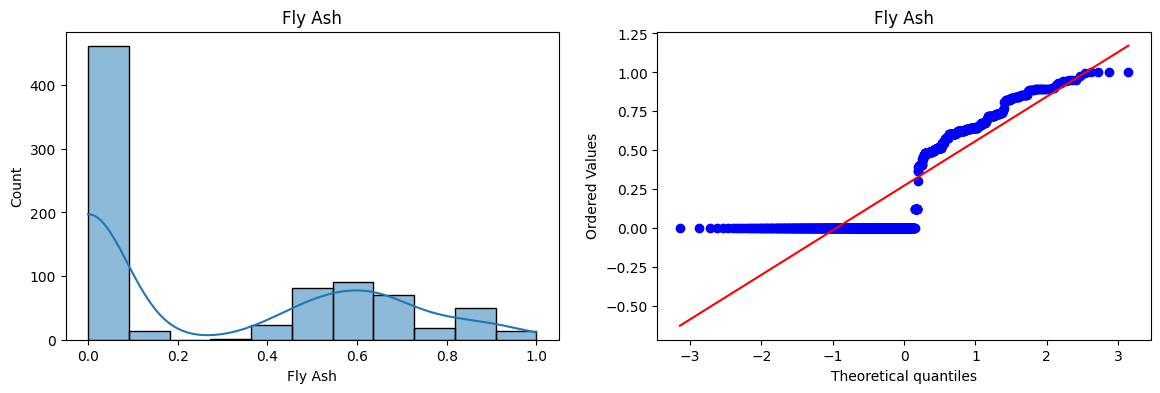

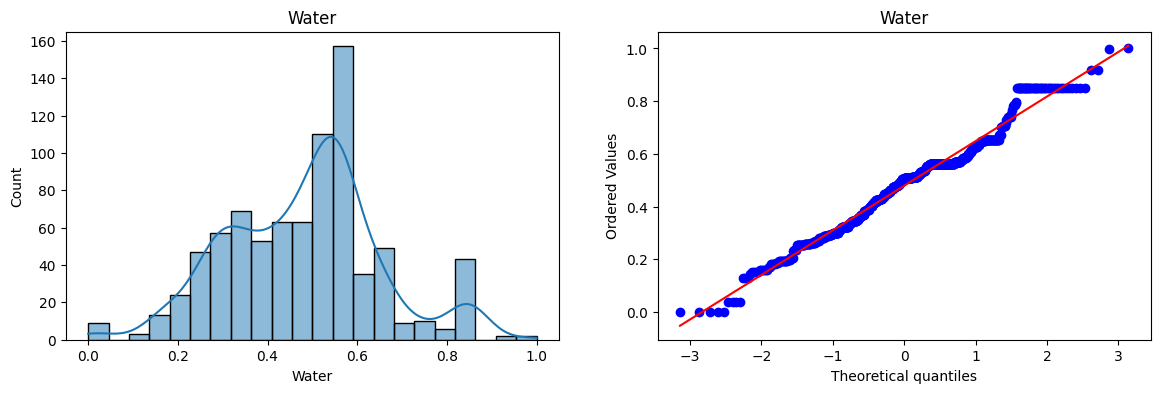

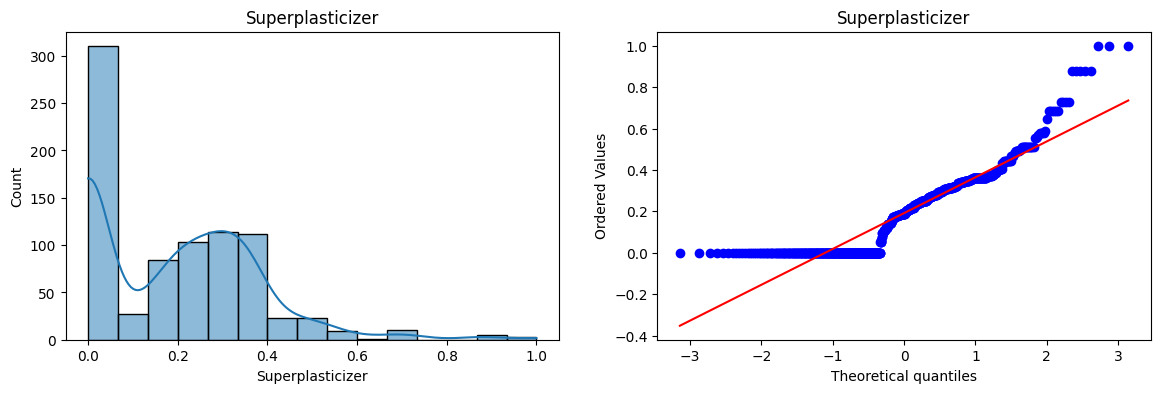

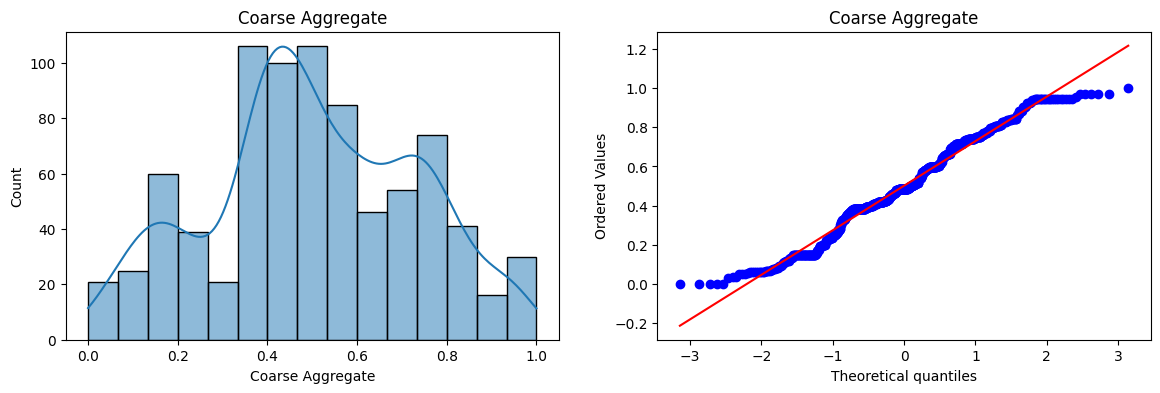

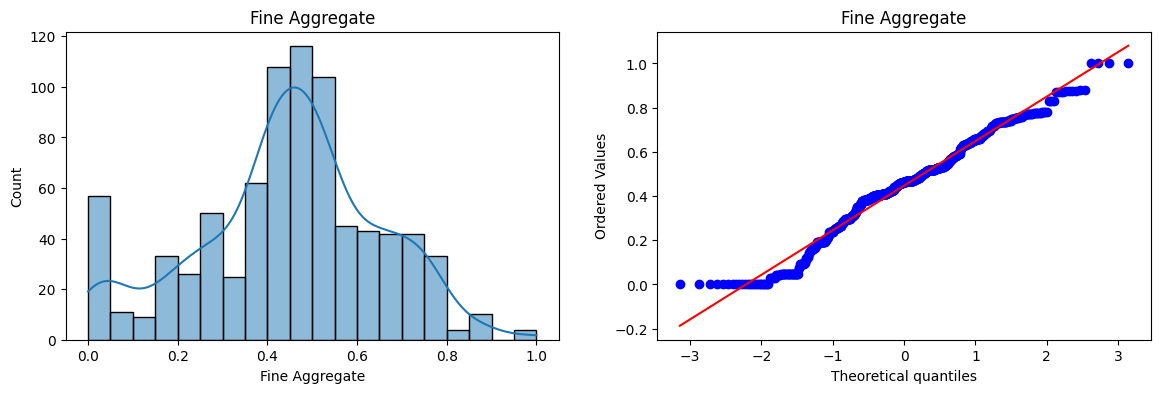

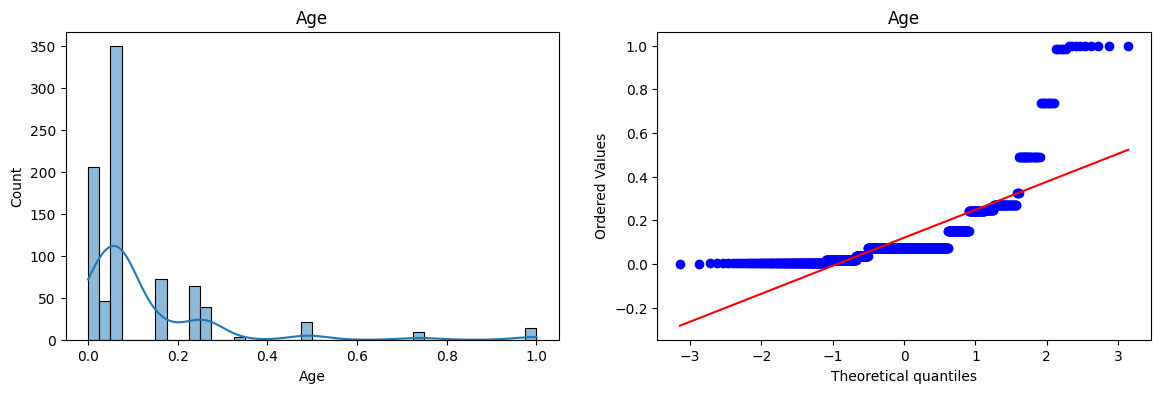

In [45]:
#Plotting the distplots without any transformation
#After scaling tho
for col in X_train_scaled.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train_scaled[col], kde=True)
    plt.title(col)
    
    plt.subplot(122)
    stats.probplot(X_train_scaled[col], dist='norm', plot = plt)
    plt.title(col)
    
    plt.show()

In [ ]:
#Applying Box_Cox Transform(tara yo ta 0 ko laagi nahuna parne lets see)
pt = PowerTransformer(method='box-cox')

X_train_transformed = pt.fit_transform(X_train_scaled+0.000001)
X_test_transformed = pt.transform(X_test_scaled + 0.00001)

pd.DataFrame({'cols':X_train_scaled.columns, 'box_cox_lambdas':pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.496054
1,Blast Furnace Slag,0.033003
2,Fly Ash,-0.054680
3,Water,0.815328
4,Superplasticizer,0.123332
5,Coarse Aggregate,0.803608
6,Fine Aggregate,0.712258
7,Age,0.165945


In [60]:
#Applying LR after box-cox

lr = LinearRegression()
lr.fit(X_train_transformed,y_train)

y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test, y_pred2)

d:\Projects\Machine-Learning\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


0.7961392413504507

In [62]:

pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X+0.00001)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformed,y, scoring='r2'))

np.float64(0.6668489649183531)

In [52]:
#Before and after box-cox transform
X_train_transformed = pd.DataFrame(X_train_transformed, columns = X_train.columns)
X_train_transformed


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,-1.250801,0.970336,1.128487,-0.275386,0.932030,-0.200925,-0.532034,0.079073
1,1.222226,0.609022,1.141762,-0.139632,0.743389,-2.105694,-0.168507,0.079073
2,0.088095,-1.082351,1.133172,-1.031836,0.792737,0.998786,0.144079,-1.610901
3,-0.127645,0.887365,1.084381,0.588046,0.724024,-1.875609,0.612376,0.079073
4,-1.094580,0.729546,1.135599,-1.092194,0.821318,1.306378,0.348923,-1.610901
...,...,...,...,...,...,...,...,...
819,0.187459,1.029026,-0.887062,-1.806330,0.833355,0.427401,0.429530,-1.610901
820,-0.178475,-1.082351,1.136258,-1.883755,0.856339,1.373421,0.399535,-0.471313
821,-0.804858,-1.082351,1.136340,-0.681547,0.792737,1.286210,0.378039,1.238535
822,1.546019,0.926467,-0.887062,0.004061,0.758175,-1.597995,0.188383,0.079073


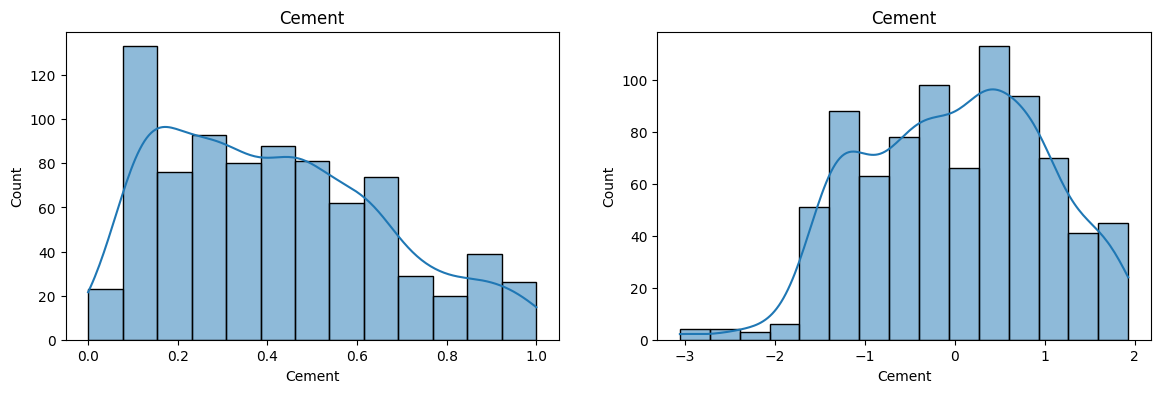

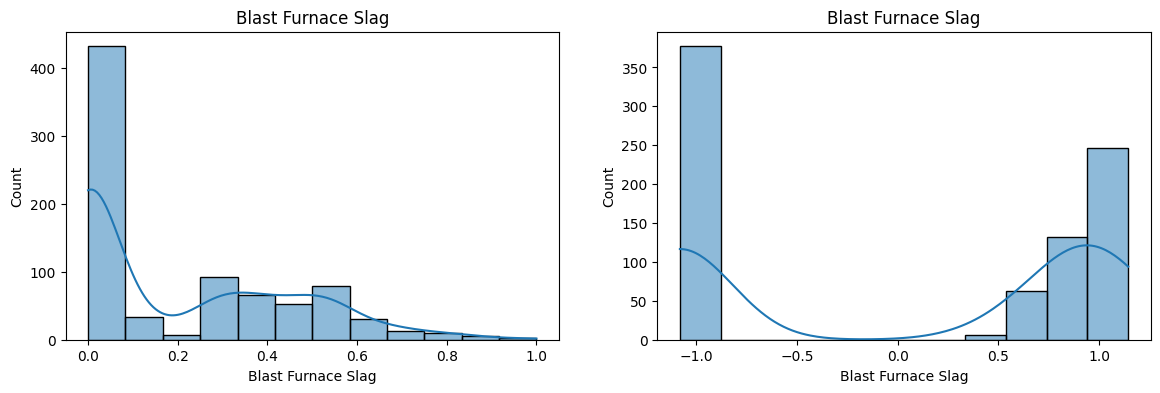

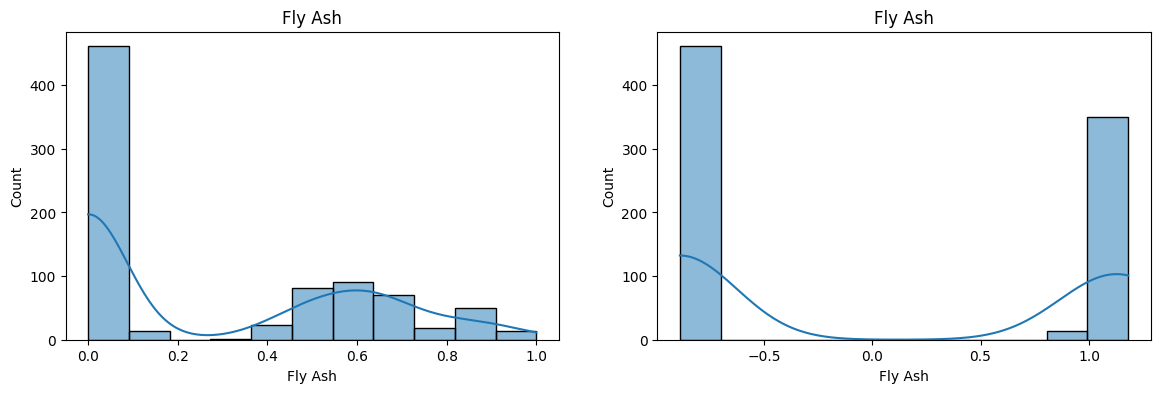

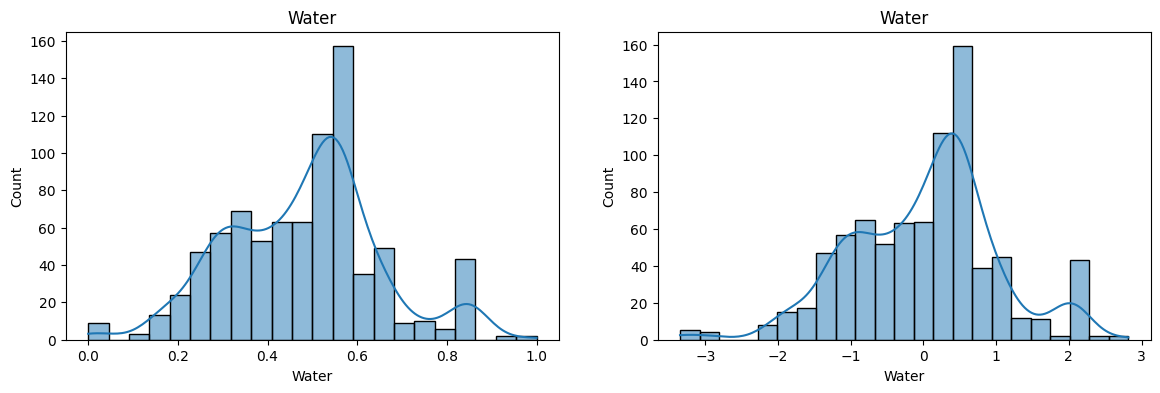

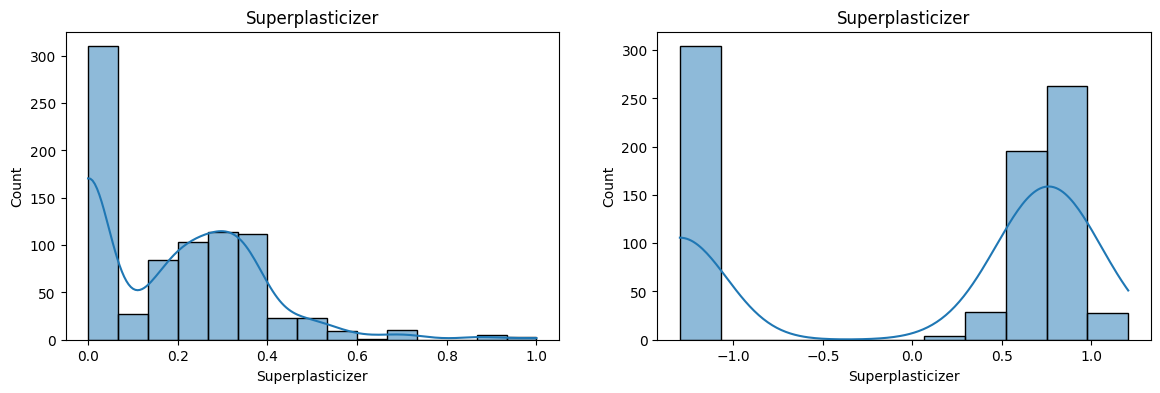

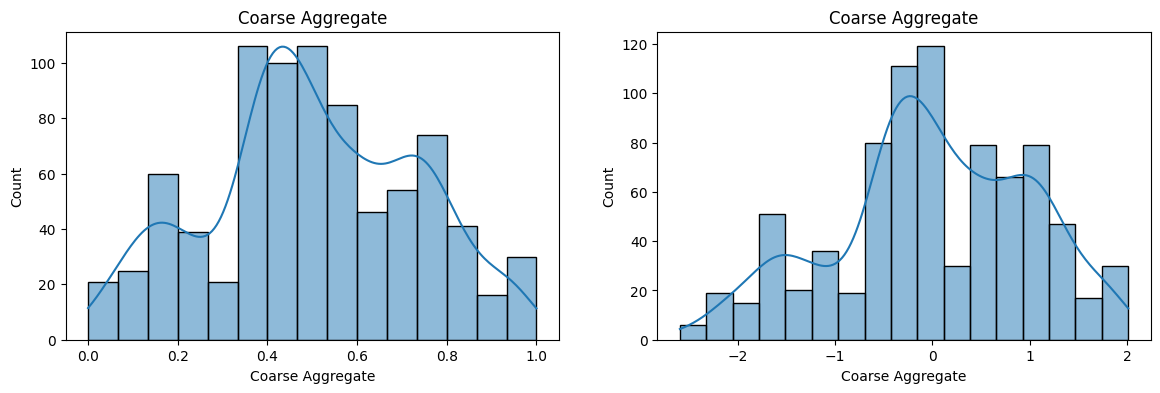

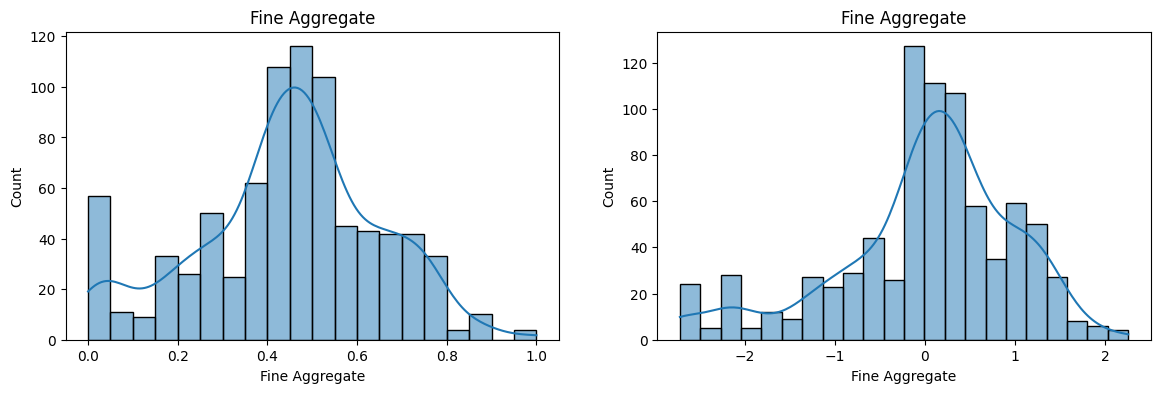

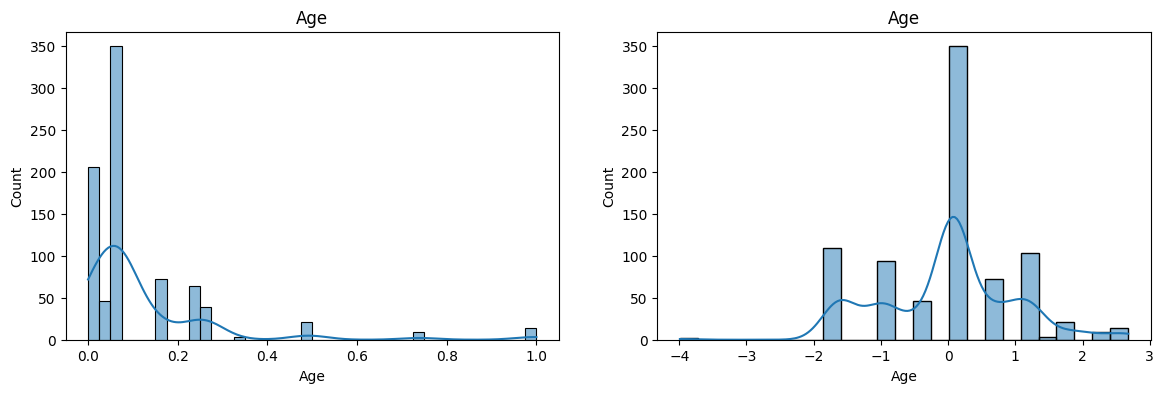

In [53]:
for col in X_train_transformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train_scaled[col], kde = True)
    plt.title(col)
    
    plt.subplot(122)
    sns.histplot(X_train_transformed[col], kde = True)
    plt.title(col)
        
    plt.show()
    

In [55]:
#Apply Yeo - Johnson
pt1 = PowerTransformer()

X_train_transformed2 = pt1.fit_transform(X_train_scaled)
X_test_transformed2 = pt1.transform(X_test_scaled)

lr = LinearRegression()
lr.fit(X_train_transformed2, y_train)

y_pred3 = lr.predict(X_test_transformed2)

print(r2_score(y_test, y_pred3))

pd.DataFrame({'cols':X_train.columns, 'Yeo-Johnson_lambdas':pt1.lambdas_})

0.8229496020109225


,cols,Yeo-Johnson_lambdas
0,Cement,-0.659497
1,Blast Furnace Slag,-2.718960
2,Fly Ash,-2.146508
3,Water,0.768008
4,Superplasticizer,-1.549738
5,Coarse Aggregate,1.020134
6,Fine Aggregate,1.568922
7,Age,-7.286351


In [65]:

pt2 = PowerTransformer()
X_transformed2 = pt2.fit_transform(X)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformed2,y, scoring='r2'))

np.float64(0.6834625126992443)

In [64]:
X_train_transformed2 = pd.DataFrame(X_train_transformed2, columns= X_train.columns)

In [66]:
#Side by Side lambdas

pd.DataFrame({'cols':X_train.columns, 'box-cox_lambdas':pt.lambdas_, 'Yeo-Johnson_lambdas':pt2.lambdas_})

,cols,box-cox_lambdas,Yeo-Johnson_lambdas
0,Cement,0.172271,0.169544
1,Blast Furnace Slag,0.028052,0.016633
2,Fly Ash,-0.037072,-0.136480
3,Water,0.809568,0.808438
4,Superplasticizer,0.114979,0.264160
5,Coarse Aggregate,1.129168,1.129395
6,Fine Aggregate,1.829625,1.830764
7,Age,0.048975,0.001771
